# 70 · Navier–Stokes

**Question.** How far does the method reach on two-dimensional Navier–Stokes: does the Carleman lift converge, what does the descriptor's time axis save at one order, and what does the lift's coupling cost on a circuit as the modes grow?

In [1]:
from pathlib import Path

from pihm import plotting
from pihm.pipeline.results import Results

results = Results.at(Path("..").resolve())
CAMPAIGNS = ("p7_build", "p7_t3", "p7_lift")
plotting.apply_style()
print(results.describe(CAMPAIGNS))

p7_build: 250 records, 250 ok
p7_t3: 64 records, 64 ok
p7_lift: 45 records, 45 ok


In [2]:
import math
from itertools import pairwise

from IPython.display import Markdown, display

from pihm.problems import ladder

builds = [
    r
    for r in results.rows("p7_build")
    if r["status"] == "ok" and r["rung"] == "R10" and not r["label"]
]


def finest(regime):
    """Return, per problem and order, the record at the order's finest n_t."""
    found = {}
    for r in builds:
        key = (r["problem"], r["carleman"])
        if r["regime"] == regime and (key not in found or r["n"] > found[key]["n"]):
            found[key] = r
    return found


def per_order(points):
    """Return the geometric mean of the error's ratio from one order to the next."""
    steps = [b[1] / a[1] for a, b in pairwise(sorted(points)) if b[0] == a[0] + 1]
    return math.exp(sum(math.log(s) for s in steps) / len(steps)) if steps else None


modes = {cutoff: count for count, cutoff in ladder.R10_MODES.items()}
points, vortex = {}, []
for (name, order), r in sorted(finest("descriptor").items()):
    strength, cutoff, window = ladder.navier_stokes_panel(name)
    if strength is None:
        vortex.append(r["lift_err_linf"])
        continue
    point = (order, r["lift_err_linf"] / strength, r["trusted"])
    points.setdefault((strength, -window), {}).setdefault(modes[cutoff], []).append(point)
series = {
    f"a/ν = {strength:g}" + ("" if window == -1 else f", T = {-window:g}"): per
    for (strength, window), per in sorted(points.items())
}

lines = [f"- Taylor–Green: the lift's error is at most {max(vortex):.1e}; its Jacobian is zero."]
for label, per in series.items():
    rates = sorted((count, per_order(values)) for count, values in per.items())
    shown = ", ".join(f"{rate:.2f} on {count} modes" for count, rate in rates if rate)
    lines.append(f"- {label}: the lift's error changes by {shown} an order.")
trusted = sum(r["trusted"] is True for r in finest("descriptor").values())
lines.append(f"- {trusted} of {len(finest('descriptor'))} of these builds are trusted.")
display(Markdown("\n".join(lines)))

- Taylor–Green: the lift's error is at most 1.1e-15; its Jacobian is zero.
- a/ν = 3: the lift's error changes by 0.02 on 12 modes, 0.08 on 20 modes, 0.13 on 28 modes, 0.15 on 48 modes an order.
- a/ν = 10: the lift's error changes by 0.07 on 12 modes, 0.27 on 20 modes, 0.44 on 28 modes, 0.49 on 48 modes an order.
- a/ν = 30: the lift's error changes by 0.24 on 12 modes, 0.62 on 20 modes, 1.15 on 28 modes, 1.54 on 48 modes an order.
- a/ν = 30, T = 0.125: the lift's error changes by 0.11 on 12 modes, 0.40 on 20 modes, 0.65 on 28 modes, 1.00 on 48 modes an order.
- 51 of 51 of these builds are trusted.

The lift's error against its order, relative to the vortex pair's norm a, at each order's finest
time axis, a line per strength and window and a panel per number of modes. Hollow markers are
untrusted kernels.

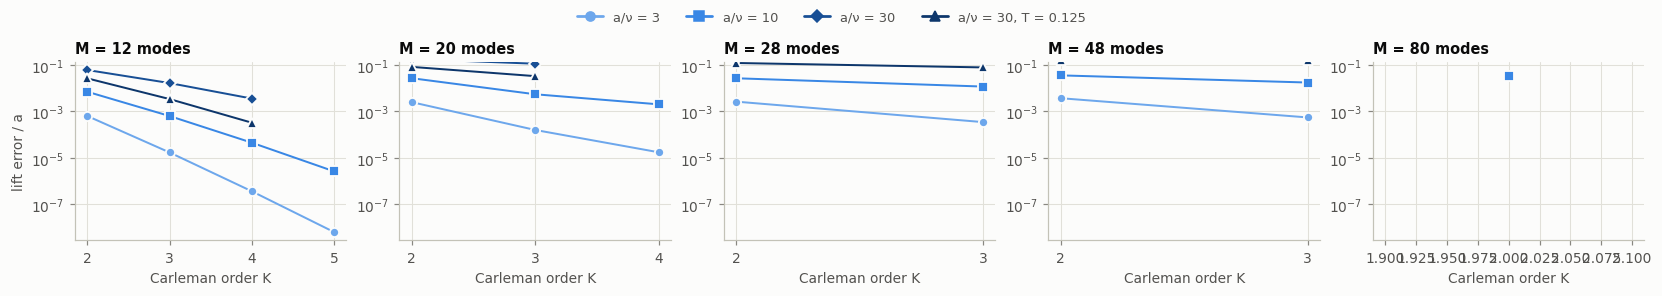

In [3]:
plotting.lift_convergence(series, "lift error / a");

In [4]:
estimates = [r for r in results.rows("p7_t3") if r["status"] == "ok" and r["carleman"] == 3]
pairs = {}
for r in estimates:
    pairs.setdefault((r["problem"], r["n"]), {})[r["regime"]] = r["degree"]
ratios = [p["standard"] / p["descriptor"] for p in pairs.values() if len(p) == 2]
display(
    Markdown(
        f"- At K = 3 the standard form's filter degree is {min(ratios):.2f}–{max(ratios):.2f} "
        f"times the descriptor's, over {len(ratios)} pairs."
    )
)

- At K = 3 the standard form's filter degree is 3.25–18.07 times the descriptor's, over 12 pairs.

The minimax filter's degree (T3) at K = 3 in both forms, a panel per problem: at one Carleman
order the forms differ only in the time axis.

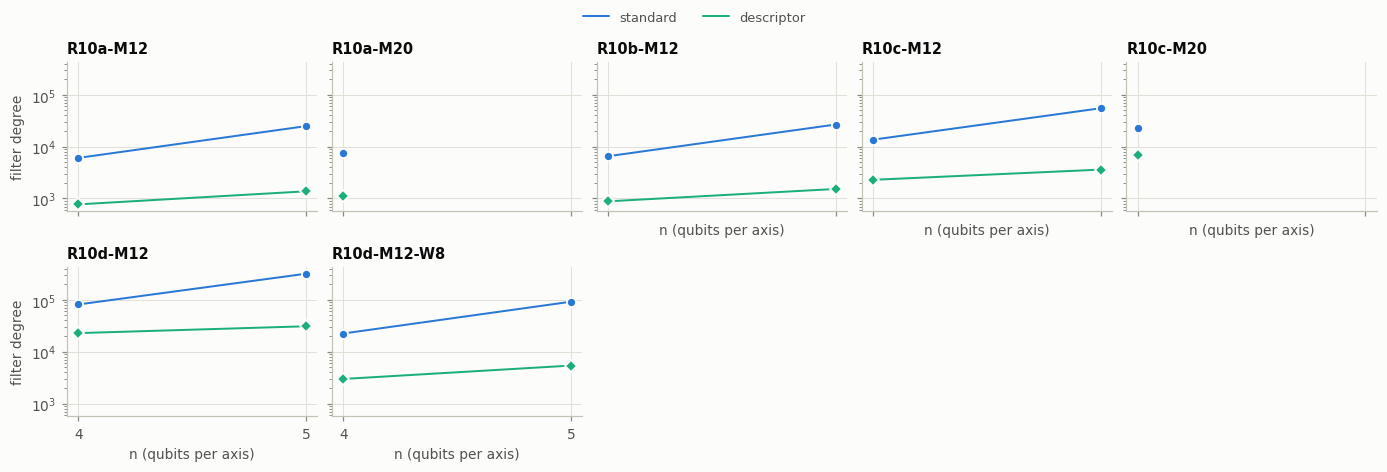

In [5]:
plotting.by_resolution(
    {form: [r for r in estimates if r["regime"] == form] for form in ("standard", "descriptor")},
    "degree",
    "filter degree",
);

In [6]:
lifts = [r for r in results.rows("p7_lift") if r["status"] == "ok" and r["verify_mode"] != "exact"]
lines = []
for order in sorted({r["carleman"] for r in lifts}):
    tensor = [r for r in lifts if r["lift"] == "tensor" and r["carleman"] == order]
    terms = {r["terms"] for r in tensor}
    widest = max(tensor, key=lambda r: r["modes"])
    lines.append(
        f"- K = {order}: the tensor layout has {sorted(terms)} terms at every M, to "
        f"{widest['modes']} modes at {widest['cx_count']:,} cx a query."
    )
display(Markdown("\n".join(lines)))

- K = 2: the tensor layout has [3] terms at every M, to 316 modes at 288,120 cx a query.
- K = 3: the tensor layout has [5] terms at every M, to 316 modes at 1,172,548 cx a query.
- K = 4: the tensor layout has [7] terms at every M, to 28 modes at 452,616 cx a query.

The cost of one query of the lift's coupling against the number of modes: the tensor layout
(solid) beside the symmetric layout's matchings (dashed), where they build, a marker per order.

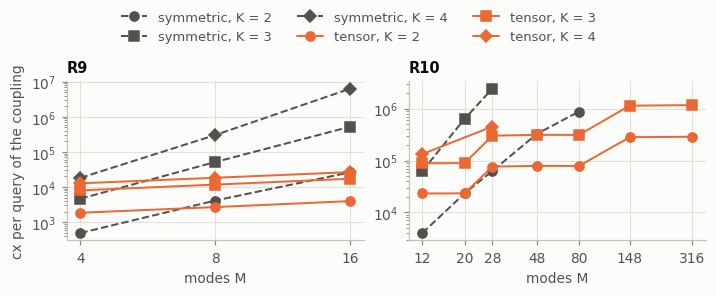

In [7]:
plotting.layout_cost(lifts, "cx_count", "cx per query of the coupling");

**What this does not show.** The Galerkin truncation's own error against a simulation of the
equation; the tensor layout's α against the norm, and its exactness, which the test suite checks.